# 10 Plot extreme changes conditioned on AMOC evolution #

In [1]:
%load_ext autoreload
%autoreload 2
    
import os
import sys
import xarray as xr
import pandas as pd
import netCDF4 as nc
import numpy as np
from dask.distributed import Client
import warnings
warnings.filterwarnings('ignore')

from cdrmip_extremes.v2 import utils, stats, plotting
from cdrmip_extremes.v2.load_processed import load_extremes
from cdrmip_extremes.v2.configs import CDR_MODELS, PROC_DIR, FIG_DIR

In [2]:
client = Client(memory_limit=None,threads_per_worker=1,n_workers=28)

## Load Data ##

In [3]:
expt = '1pctCO2-cdr'

#### From previous notebook we have ####

In [4]:
amoc_changes = {
    'CESM2': -4.46,
    'CNRM-ESM2-1': -3.35,
    'MIROC-ES2L': -2.31,
    'NorESM2-LM': -1.02,
    'UKESM1-0-LL': 1.25,
    'GFDL-ESM4': 1.88,
    'ACCESS-ESM1-5': 3.48,
    'CanESM5': 3.53
}
models_amoc_ordered = list(amoc_changes.keys())
models_amoc_ordered

['CESM2',
 'CNRM-ESM2-1',
 'MIROC-ES2L',
 'NorESM2-LM',
 'UKESM1-0-LL',
 'GFDL-ESM4',
 'ACCESS-ESM1-5',
 'CanESM5']

In [15]:
np.median(np.array(list(amoc_changes.values())))

0.11499999999999999

In [5]:
ext_data = load_extremes(
    PROC_DIR, 'CDRMIP',
    outputs=['exceedances_median_multimodel', 'branch_differences_median_multimodel','agreement','gwl_period_extremes'],
    model_order=CDR_MODELS,
)
exceedances = ext_data['exceedances_median_multimodel']
differences = ext_data['branch_differences_median_multimodel']
agreement = ext_data['agreement']
ext_month_tas = ext_data['gwl_period_extremes']

  sort_models: no order defined for ['multi_model_median'], appending at end
  sort_models: no order defined for ['multi_model_median'], appending at end


In [6]:
heat_freq_differences = {
    model: differences[model][expt]['heat'] for model in models_amoc_ordered
}
cold_freq_differences = {
    model: differences[model][expt]['cold'] for model in models_amoc_ordered
}

#### Load extreme month temperature data ####

In [7]:
ext_month_tas = {
    model: ext_month_tas[model][expt][None] for model in models_amoc_ordered
}

In [8]:
ext_month_tas_differences = {
    model: stats.gwl_branch_difference(ds)
    for model, ds in ext_month_tas.items()
}

## Plot ##

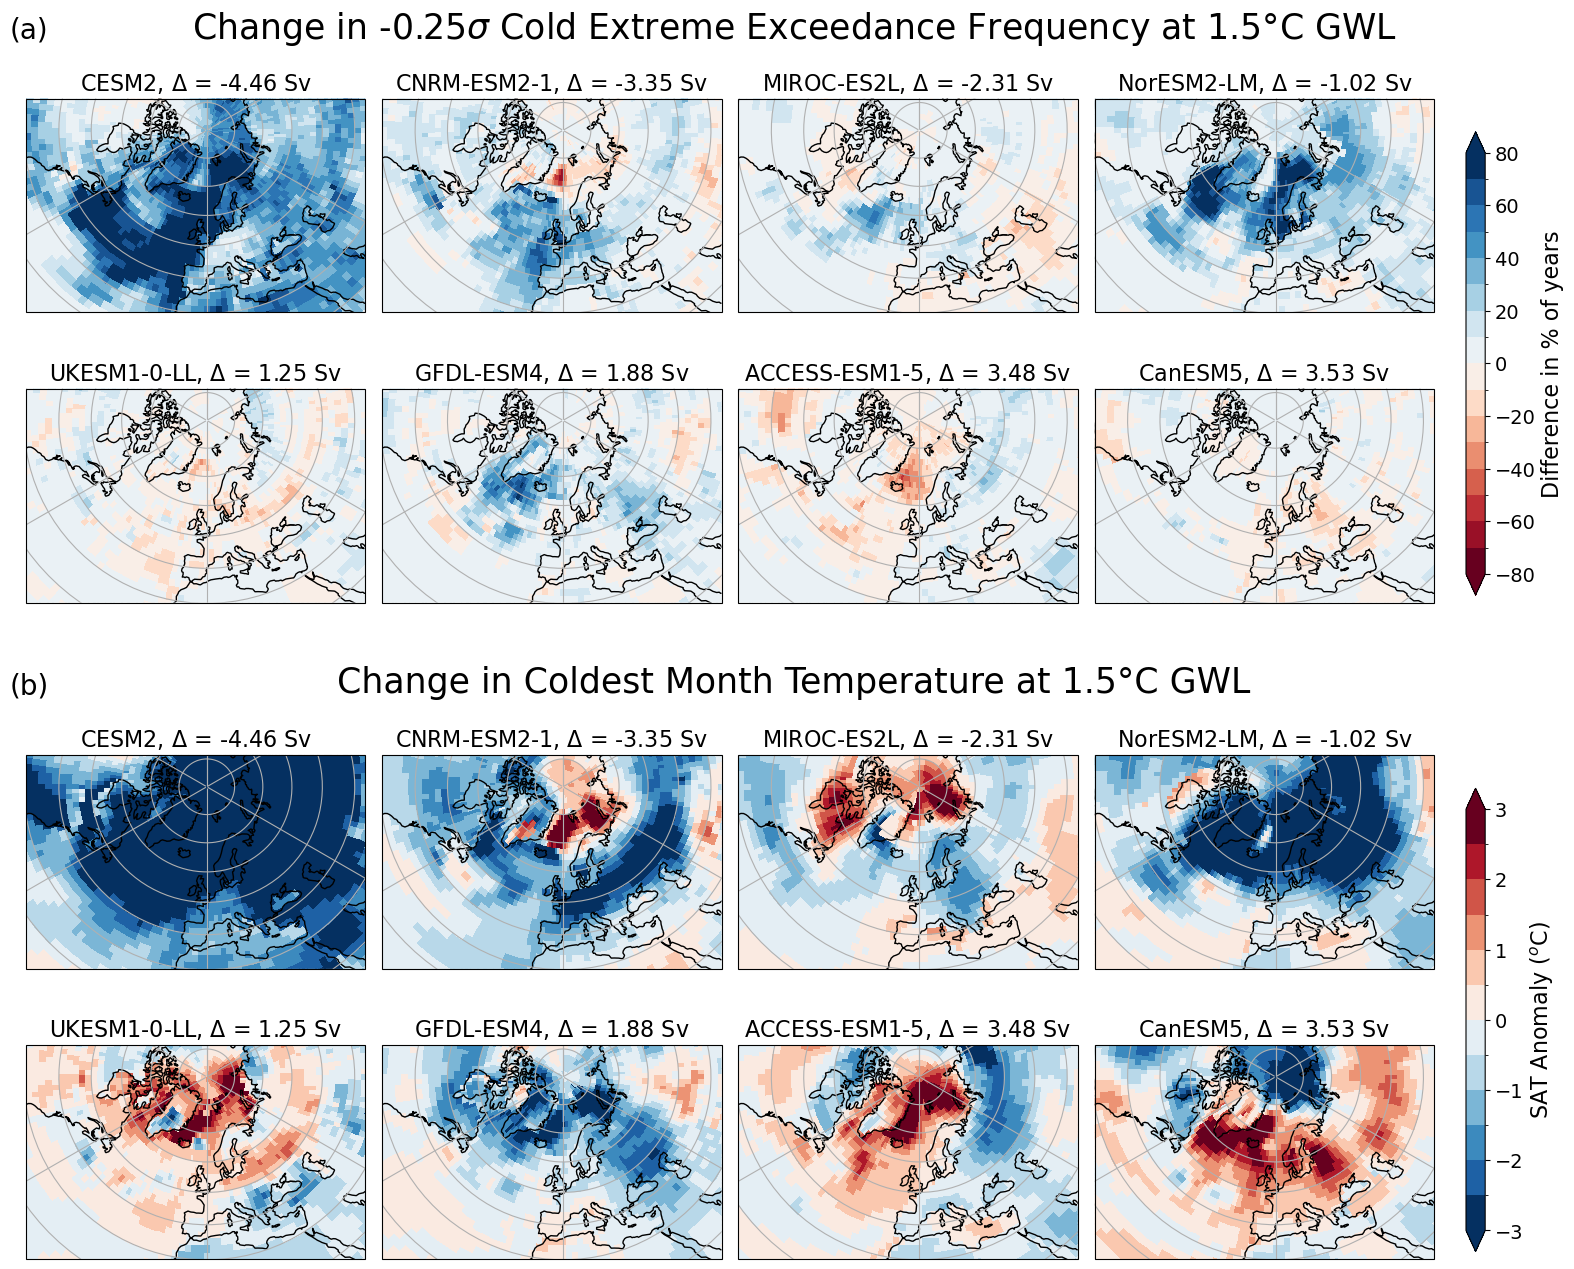

In [34]:
fig = plotting.plot_freq_and_intens_amoc_stereo(
    'Cold',
    cold_freq_differences,
    ext_month_tas_differences,
    1.5,
    'sigma1',
    freq_levels=np.linspace(-80, 80, 17),
    intens_levels=np.linspace(-3, 3, 13),
    amoc_changes=amoc_changes,
)

fig.savefig(
    FIG_DIR / "main" / "figure8.jpg",
    dpi=300,
    bbox_inches="tight",
    pil_kwargs={"quality": 95}
)

## Plot mean changes grouped by AMOC sensitivity ##

In [15]:
AMOC_models = ["CESM2","MIROC-ES2L","NorESM2-LM",'CNRM-ESM2-1',]
non_AMOC_models = ['ACCESS-ESM1-5','CanESM5','GFDL-ESM4',"UKESM1-0-LL"]

In [16]:
AMOC_heat_freq_mean = xr.concat([heat_freq_differences[model] for model in AMOC_models],
                                  dim='model',
                                 compat='override',
                                 coords='minimal').mean(dim='model')
non_AMOC_heat_freq_mean = xr.concat([heat_freq_differences[model] for model in non_AMOC_models],
                                      dim='model',
                                      compat='override',
                                      coords='minimal').mean(dim='model')
AMOC_cold_freq_mean = xr.concat([cold_freq_differences[model] for model in AMOC_models],
                                  dim='model',
                                 compat='override',
                                 coords='minimal').mean(dim='model')
non_AMOC_cold_freq_mean = xr.concat([cold_freq_differences[model] for model in non_AMOC_models],
                                      dim='model',
                                      compat='override',
                                      coords='minimal').mean(dim='model')
AMOC_ext_month_tas_mean = xr.concat([ext_month_tas_differences[model].tas for model in AMOC_models],
                                  dim='model',
                                 compat='override',
                                 coords='minimal').mean(dim='model')
non_AMOC_ext_month_tas_mean = xr.concat([ext_month_tas_differences[model].tas for model in non_AMOC_models],
                                      dim='model',
                                      compat='override',
                                      coords='minimal').mean(dim='model')

In [12]:
cbar_kwargs = {
        "fraction": 0.02, "aspect": 20,
        "label": "% Years", 'orientation': 'vertical',
        'location': 'right', 'pad': 0.01,
        'anchor': (0.5, -4), 'extend': 'both'
    }

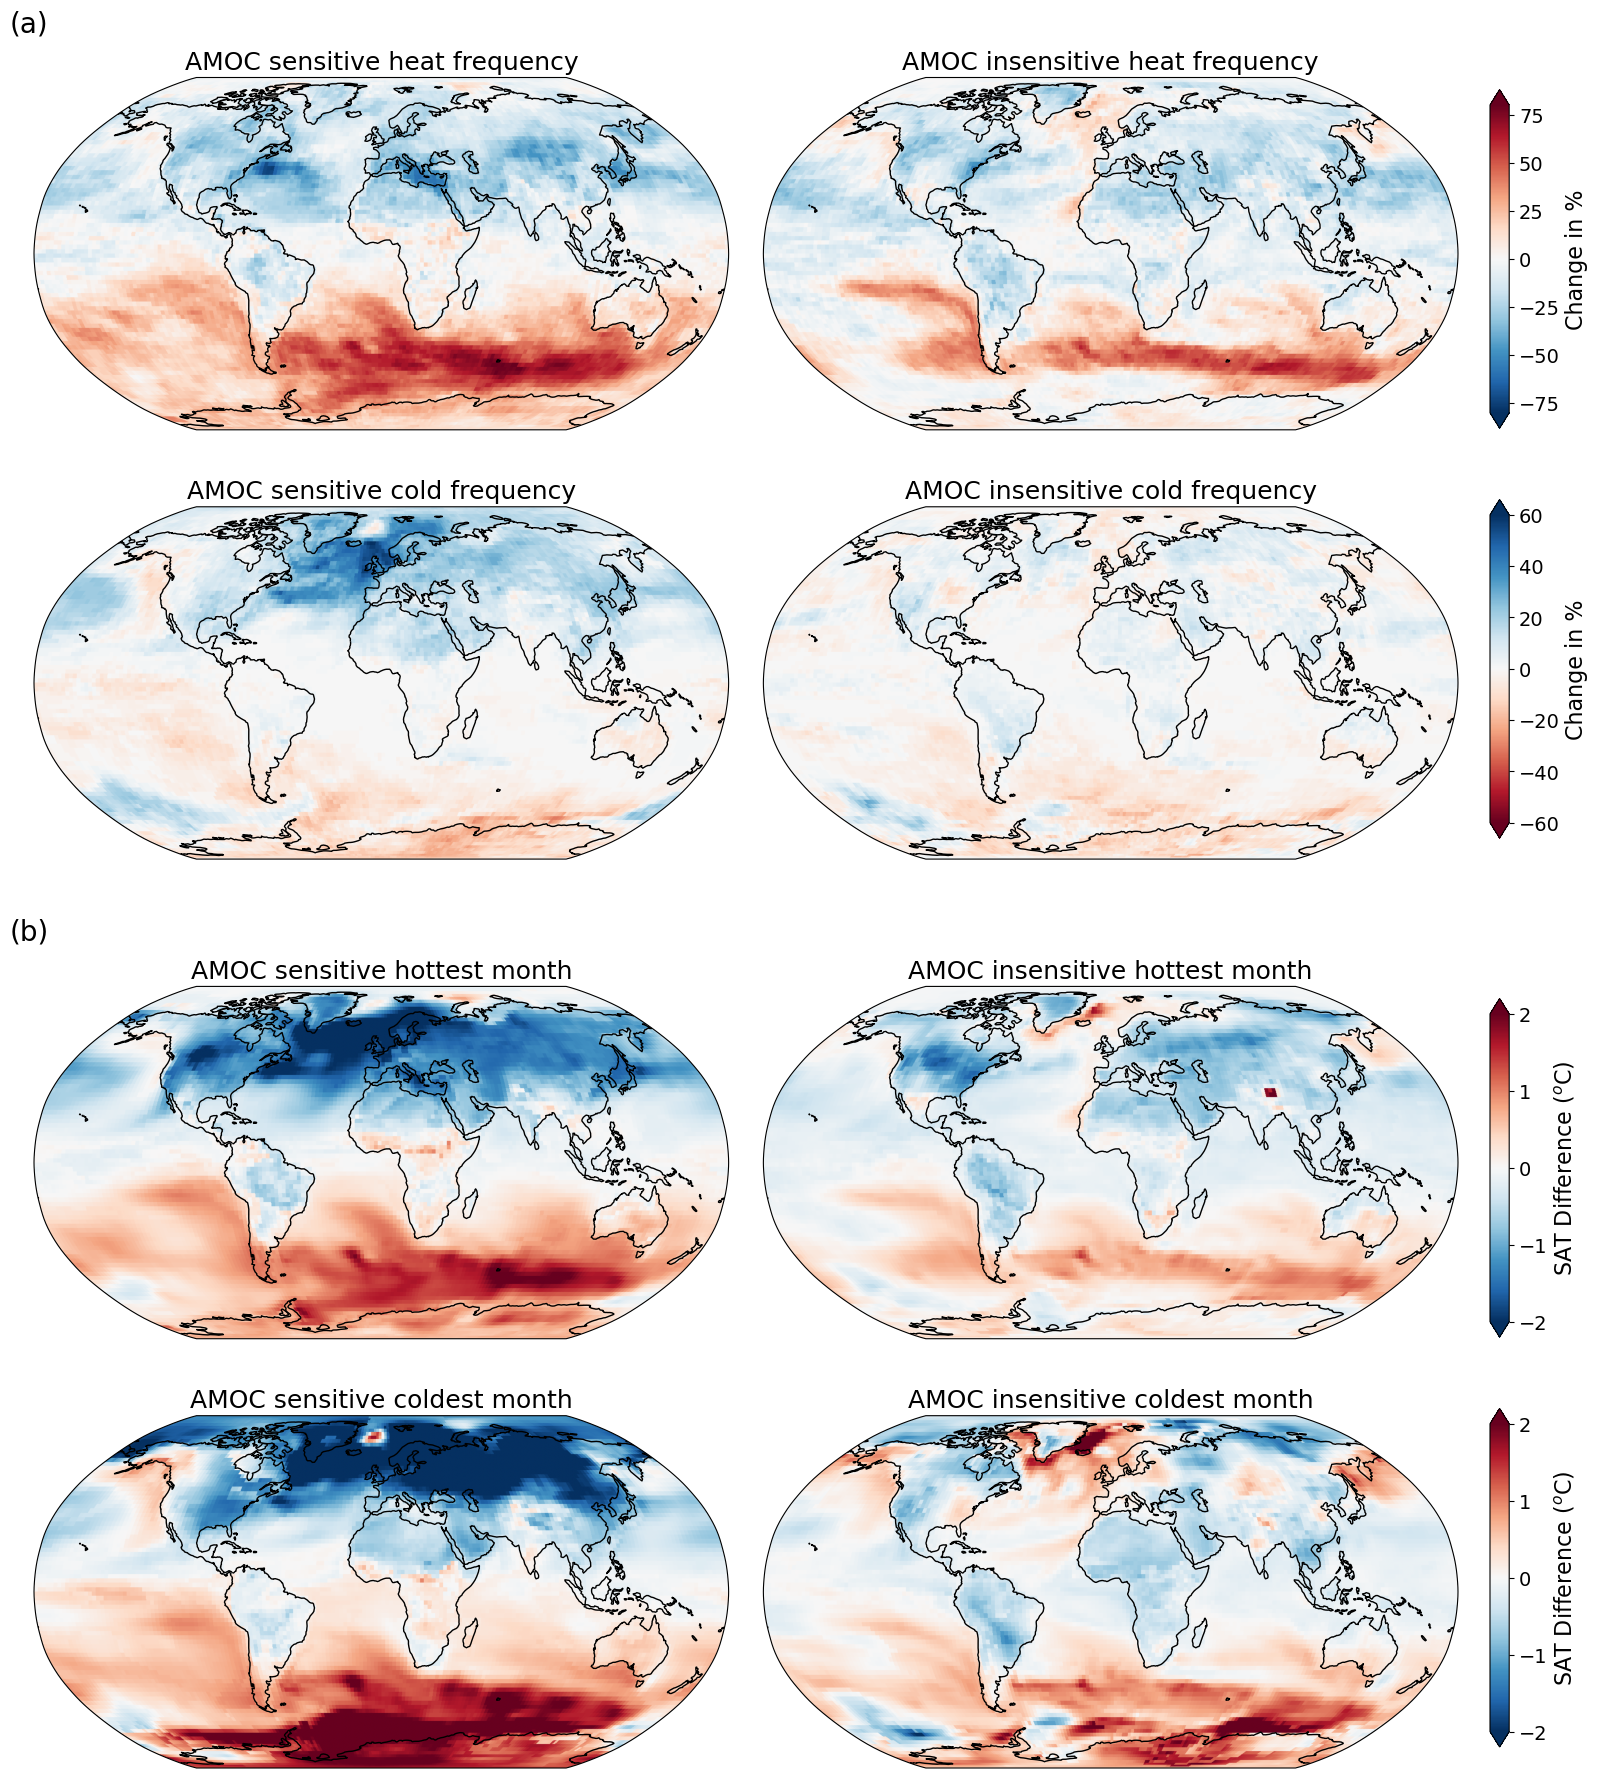

In [32]:
to_plot_hottest = {
    'AMOC sensitive hottest month':AMOC_ext_month_tas_mean.sel(extrema='heat',gwl=1.5),
    'AMOC insensitive hottest month':non_AMOC_ext_month_tas_mean.sel(extrema='heat',gwl=1.5),
}
to_plot_coldest = {
    'AMOC sensitive coldest month':AMOC_ext_month_tas_mean.sel(extrema='cold',gwl=1.5),
    'AMOC insensitive coldest month':non_AMOC_ext_month_tas_mean.sel(extrema='cold',gwl=1.5),
}

to_plot_heat_freq = {
    'AMOC sensitive heat frequency':AMOC_heat_freq_mean.sel(gwl=1.5).sigma2,
    'AMOC insensitive heat frequency':non_AMOC_heat_freq_mean.sel(gwl=1.5).sigma2,
}
to_plot_cold_freq = {
    'AMOC sensitive cold frequency':AMOC_cold_freq_mean.sel(gwl=1.5).sigma1,
    'AMOC insensitive cold frequency':non_AMOC_cold_freq_mean.sel(gwl=1.5).sigma1,
}

freq_rows = [
    {'data': to_plot_heat_freq,  'cmap': 'RdBu_r', 'vmin': -80, 'vmax': 80, 'cbar_label': 'Change in %'},
    {'data': to_plot_cold_freq,  'cmap': 'RdBu',   'vmin': -60, 'vmax': 60, 'cbar_label': 'Change in %'},
]
tas_rows = [
    {'data': to_plot_hottest,  'cmap': 'RdBu_r', 'vmin': -2, 'vmax': 2, 'cbar_label': 'SAT Difference ($^o$C)'},
    {'data': to_plot_coldest,  'cmap': 'RdBu_r', 'vmin': -2, 'vmax': 2, 'cbar_label': 'SAT Difference ($^o$C)'},
]

fig = plotting.plot_mean_freq_and_tas_stacked(freq_rows, tas_rows)

fig.savefig(
    FIG_DIR / "main" / "figure9.jpg",
    dpi=300,
    bbox_inches="tight",
    pil_kwargs={"quality": 95}
)

## Plot changes but only taking the three either side

In [9]:
AMOC_models = ["CESM2","MIROC-ES2L",'CNRM-ESM2-1',]
non_AMOC_models = ['ACCESS-ESM1-5','CanESM5','GFDL-ESM4']

In [11]:
AMOC_heat_freq_mean = xr.concat([heat_freq_differences[model] for model in AMOC_models],
                                  dim='model',
                                 compat='override',
                                 coords='minimal').mean(dim='model')
non_AMOC_heat_freq_mean = xr.concat([heat_freq_differences[model] for model in non_AMOC_models],
                                      dim='model',
                                      compat='override',
                                      coords='minimal').mean(dim='model')
AMOC_cold_freq_mean = xr.concat([cold_freq_differences[model] for model in AMOC_models],
                                  dim='model',
                                 compat='override',
                                 coords='minimal').mean(dim='model')
non_AMOC_cold_freq_mean = xr.concat([cold_freq_differences[model] for model in non_AMOC_models],
                                      dim='model',
                                      compat='override',
                                      coords='minimal').mean(dim='model')
AMOC_ext_month_tas_mean = xr.concat([ext_month_tas_differences[model].tas for model in AMOC_models],
                                  dim='model',
                                 compat='override',
                                 coords='minimal').mean(dim='model')
non_AMOC_ext_month_tas_mean = xr.concat([ext_month_tas_differences[model].tas for model in non_AMOC_models],
                                      dim='model',
                                      compat='override',
                                      coords='minimal').mean(dim='model')

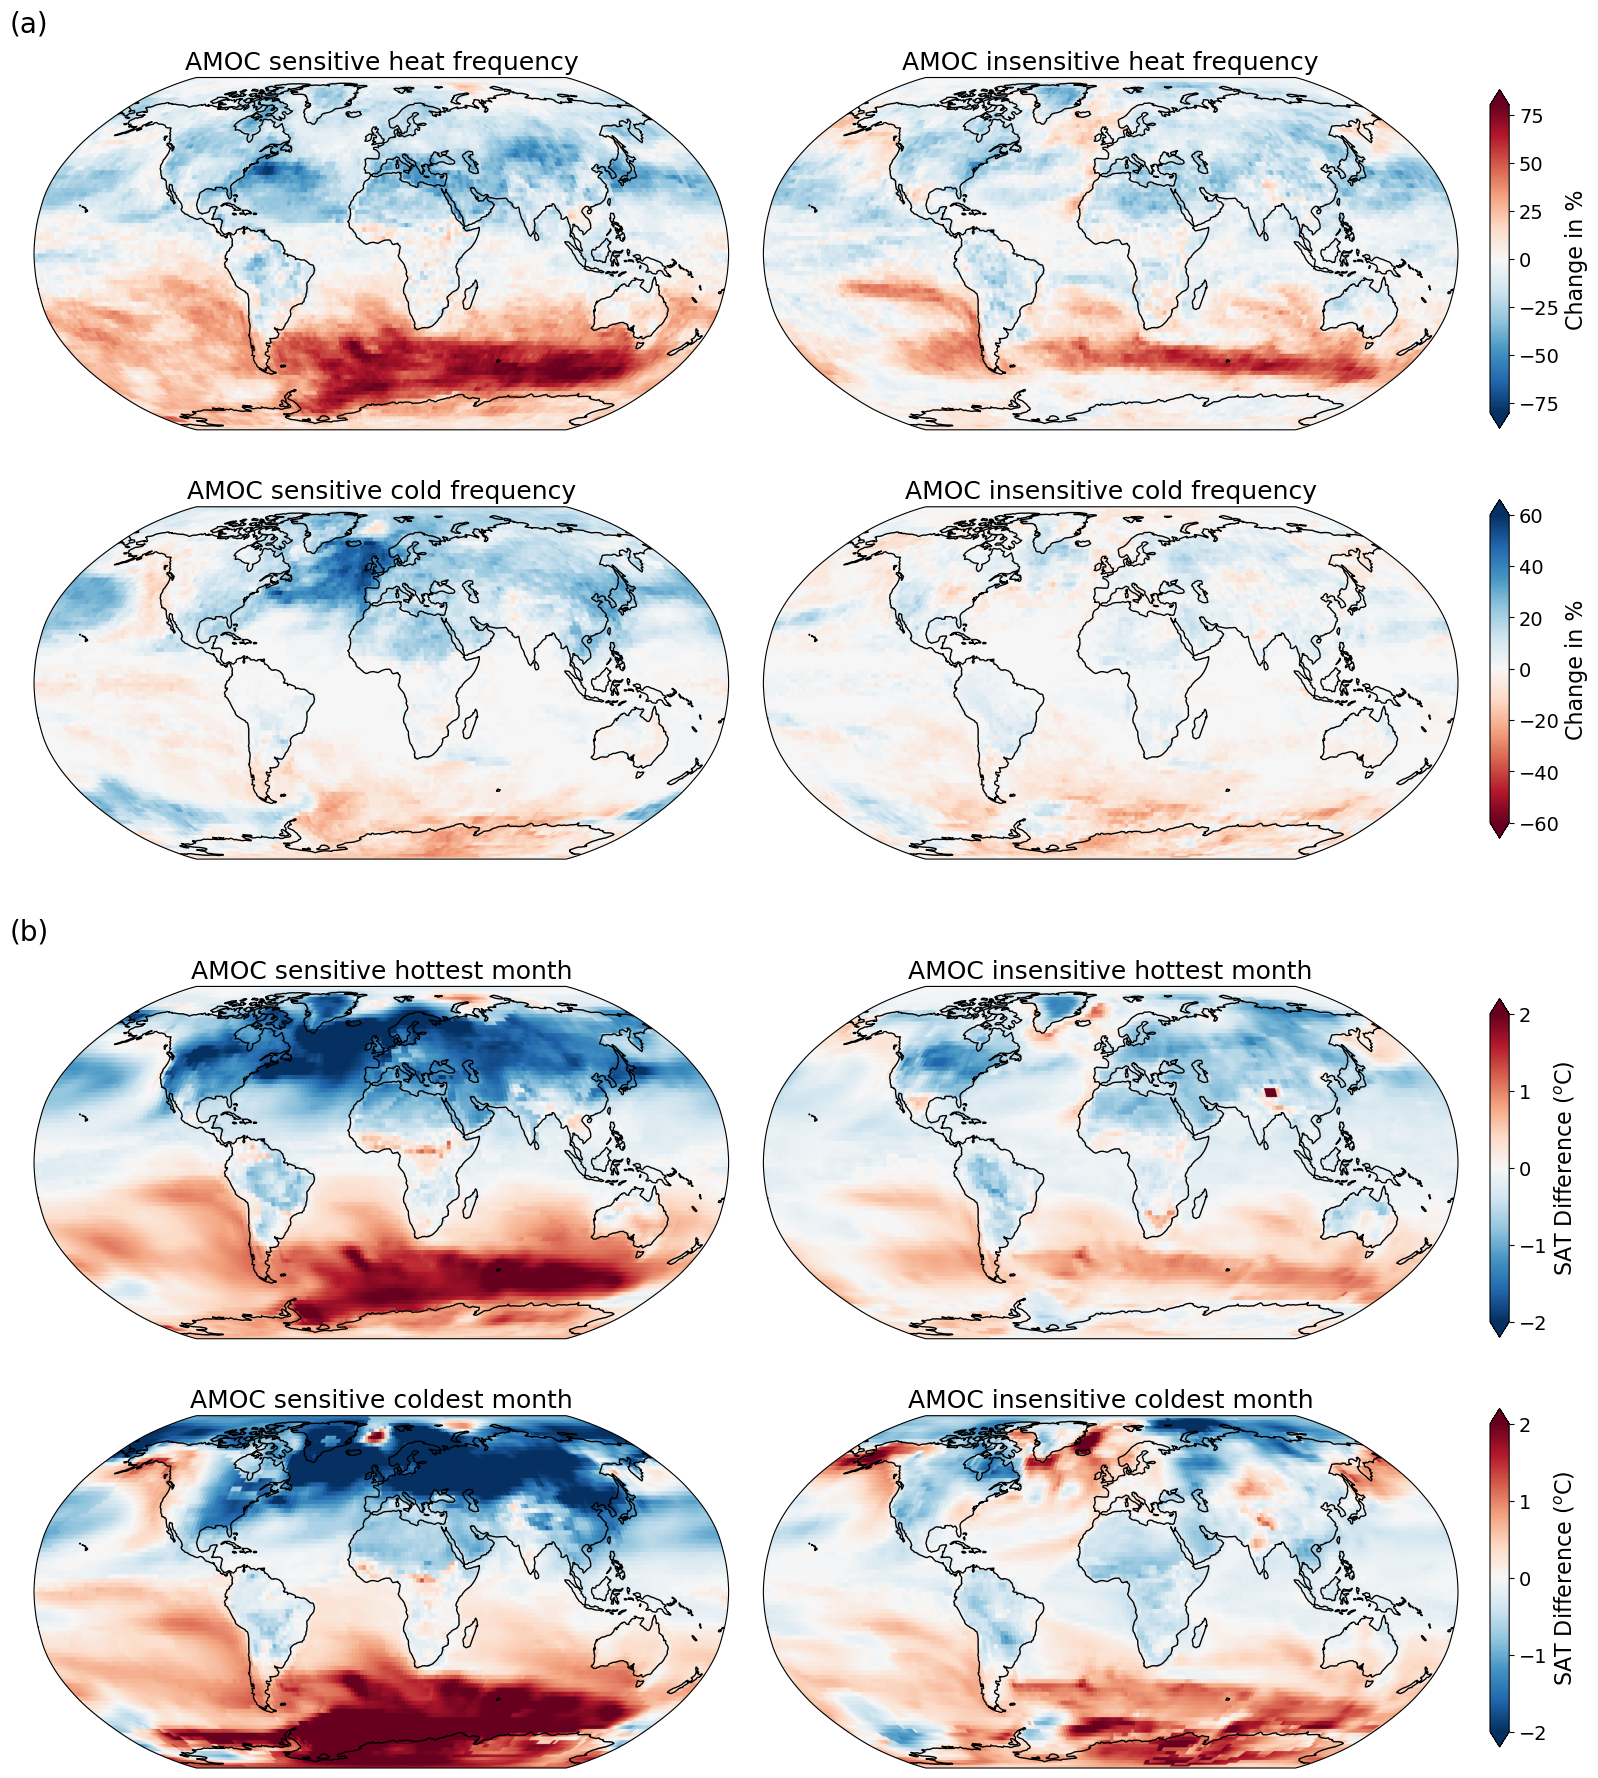

In [13]:
to_plot_hottest = {
    'AMOC sensitive hottest month':AMOC_ext_month_tas_mean.sel(extrema='heat',gwl=1.5),
    'AMOC insensitive hottest month':non_AMOC_ext_month_tas_mean.sel(extrema='heat',gwl=1.5),
}
to_plot_coldest = {
    'AMOC sensitive coldest month':AMOC_ext_month_tas_mean.sel(extrema='cold',gwl=1.5),
    'AMOC insensitive coldest month':non_AMOC_ext_month_tas_mean.sel(extrema='cold',gwl=1.5),
}

to_plot_heat_freq = {
    'AMOC sensitive heat frequency':AMOC_heat_freq_mean.sel(gwl=1.5).sigma2,
    'AMOC insensitive heat frequency':non_AMOC_heat_freq_mean.sel(gwl=1.5).sigma2,
}
to_plot_cold_freq = {
    'AMOC sensitive cold frequency':AMOC_cold_freq_mean.sel(gwl=1.5).sigma1,
    'AMOC insensitive cold frequency':non_AMOC_cold_freq_mean.sel(gwl=1.5).sigma1,
}

freq_rows = [
    {'data': to_plot_heat_freq,  'cmap': 'RdBu_r', 'vmin': -80, 'vmax': 80, 'cbar_label': 'Change in %'},
    {'data': to_plot_cold_freq,  'cmap': 'RdBu',   'vmin': -60, 'vmax': 60, 'cbar_label': 'Change in %'},
]
tas_rows = [
    {'data': to_plot_hottest,  'cmap': 'RdBu_r', 'vmin': -2, 'vmax': 2, 'cbar_label': 'SAT Difference ($^o$C)'},
    {'data': to_plot_coldest,  'cmap': 'RdBu_r', 'vmin': -2, 'vmax': 2, 'cbar_label': 'SAT Difference ($^o$C)'},
]

fig = plotting.plot_mean_freq_and_tas_stacked(freq_rows, tas_rows)

fig.savefig(
    FIG_DIR / "main" / "figure9.jpg",
    dpi=300,
    bbox_inches="tight",
    pil_kwargs={"quality": 95}
)